# Figure 1 A–B — hypothesis and an example session

Each panel is saved to `../figure_output/<Fig>/` under its own name.

In [1]:
# Data: ../csv/Fig1_AB_hypothesis_example/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'Fig1_AB_hypothesis_example'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import final_figs as F                     # print styles, saving, stars

## Fig 1A — hypothesis schematic

Copied from its vector source (a schematic is not drawn by code).

- Source: `reports/new_planc/individual_fig_main/fig1_A_Hypothesis_ver7r.svg` (the standalone version; its layout matches the submitted panel). The "SYSTEM PROPERTIES / Flexibility, system computation, information integration" text of the submitted panel is not in ver7r; it is live text only in the assembled `reports/new_planc/nature/Fig_1.svg`, where "Flexibility" is spelled "Flexiblity".

copied fig1_A_Hypothesis_ver7r -> figure_output\Fig1\Fig1_A_hypothesis ['.svg', '.png (inkscape)']


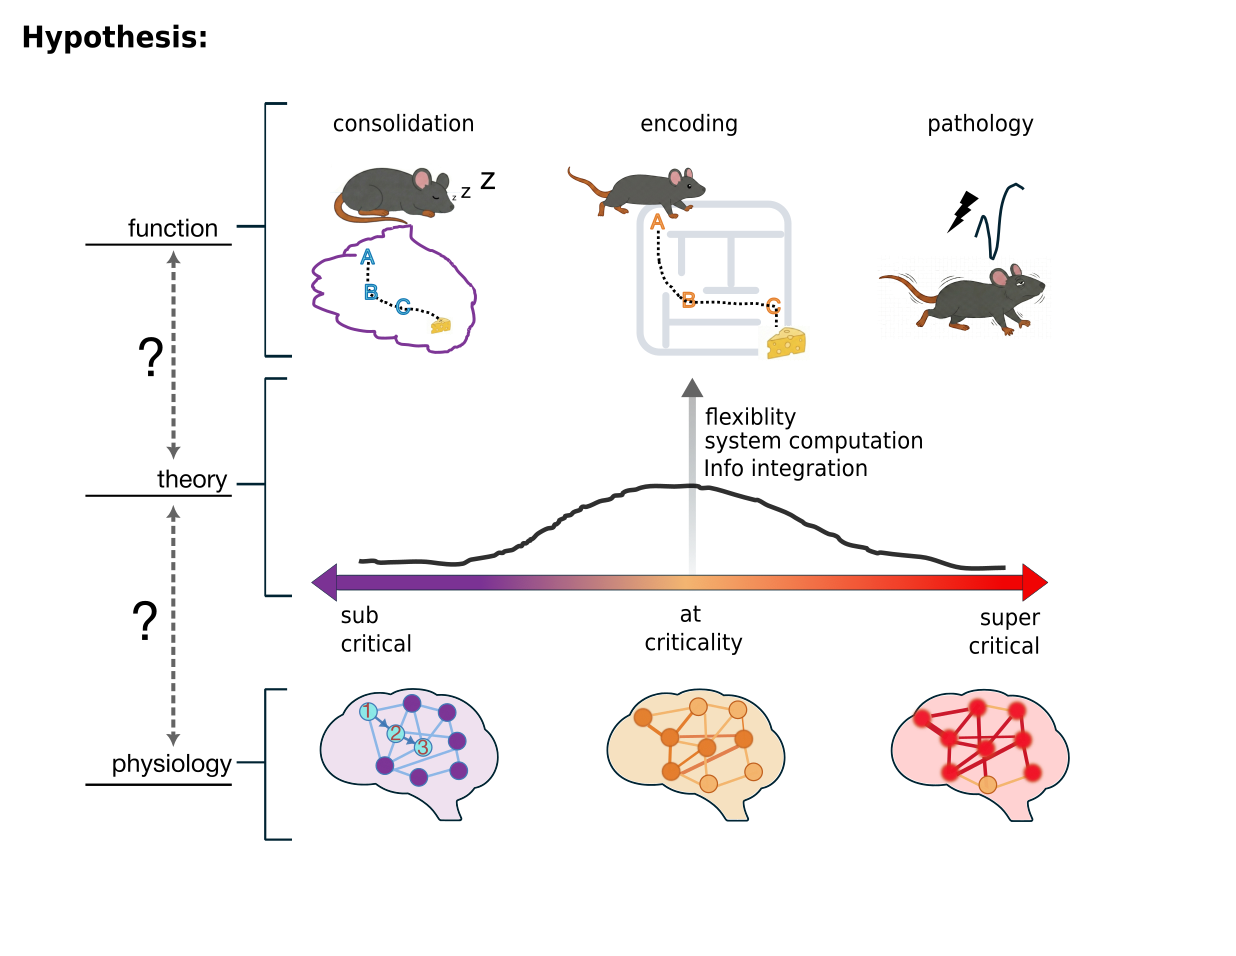

In [2]:
# ---- data (../csv) ----
src = str(CSV / "assets" / "fig1_A_Hypothesis_ver7r.svg")   # the schematic's vector source
# ---- the same from the recordings, with analysis_scripts/: ----
# src = os.path.join(F.REPO, "reports", "new_planc", "individual_fig_main", "fig1_A_Hypothesis_ver7r.svg")
png = F.copy(src, "Fig1_A_hypothesis")
F.show(png)

## Fig 1B — example session, all window features over time

PPP20 day 5, 80 min: state bar; population firing rate; E/I balance (log E/I rate); synchrony (E units active per 50 ms); theta power ratio; SWR rate; d2 (2024 Euclidean, AR p = 20, 40 ms bins, full window), coloured by state.

- Drawn **at final size** for the assembled figure (`Fig1_assemble.ipynb`; 180 mm wide, Arial 5–7 pt, `F.final_style`). 72 × 158 mm figsize → 70.4 × 156.4 mm, 6 pt text, 0.6 pt traces.
- Producer: `notebooks/exploration/revision/fig1c_example_traces.py` (its `main()`; reads the session from W: read-only); its size knobs (`FIGSIZE, LW, STATE_LABELPAD, DPI`) and `OUT` are set here, defaults unchanged.
- The rerun's window table is written to a temp file and compared against the stored `data/revision/log/fig1c_example_traces.csv` for equality.

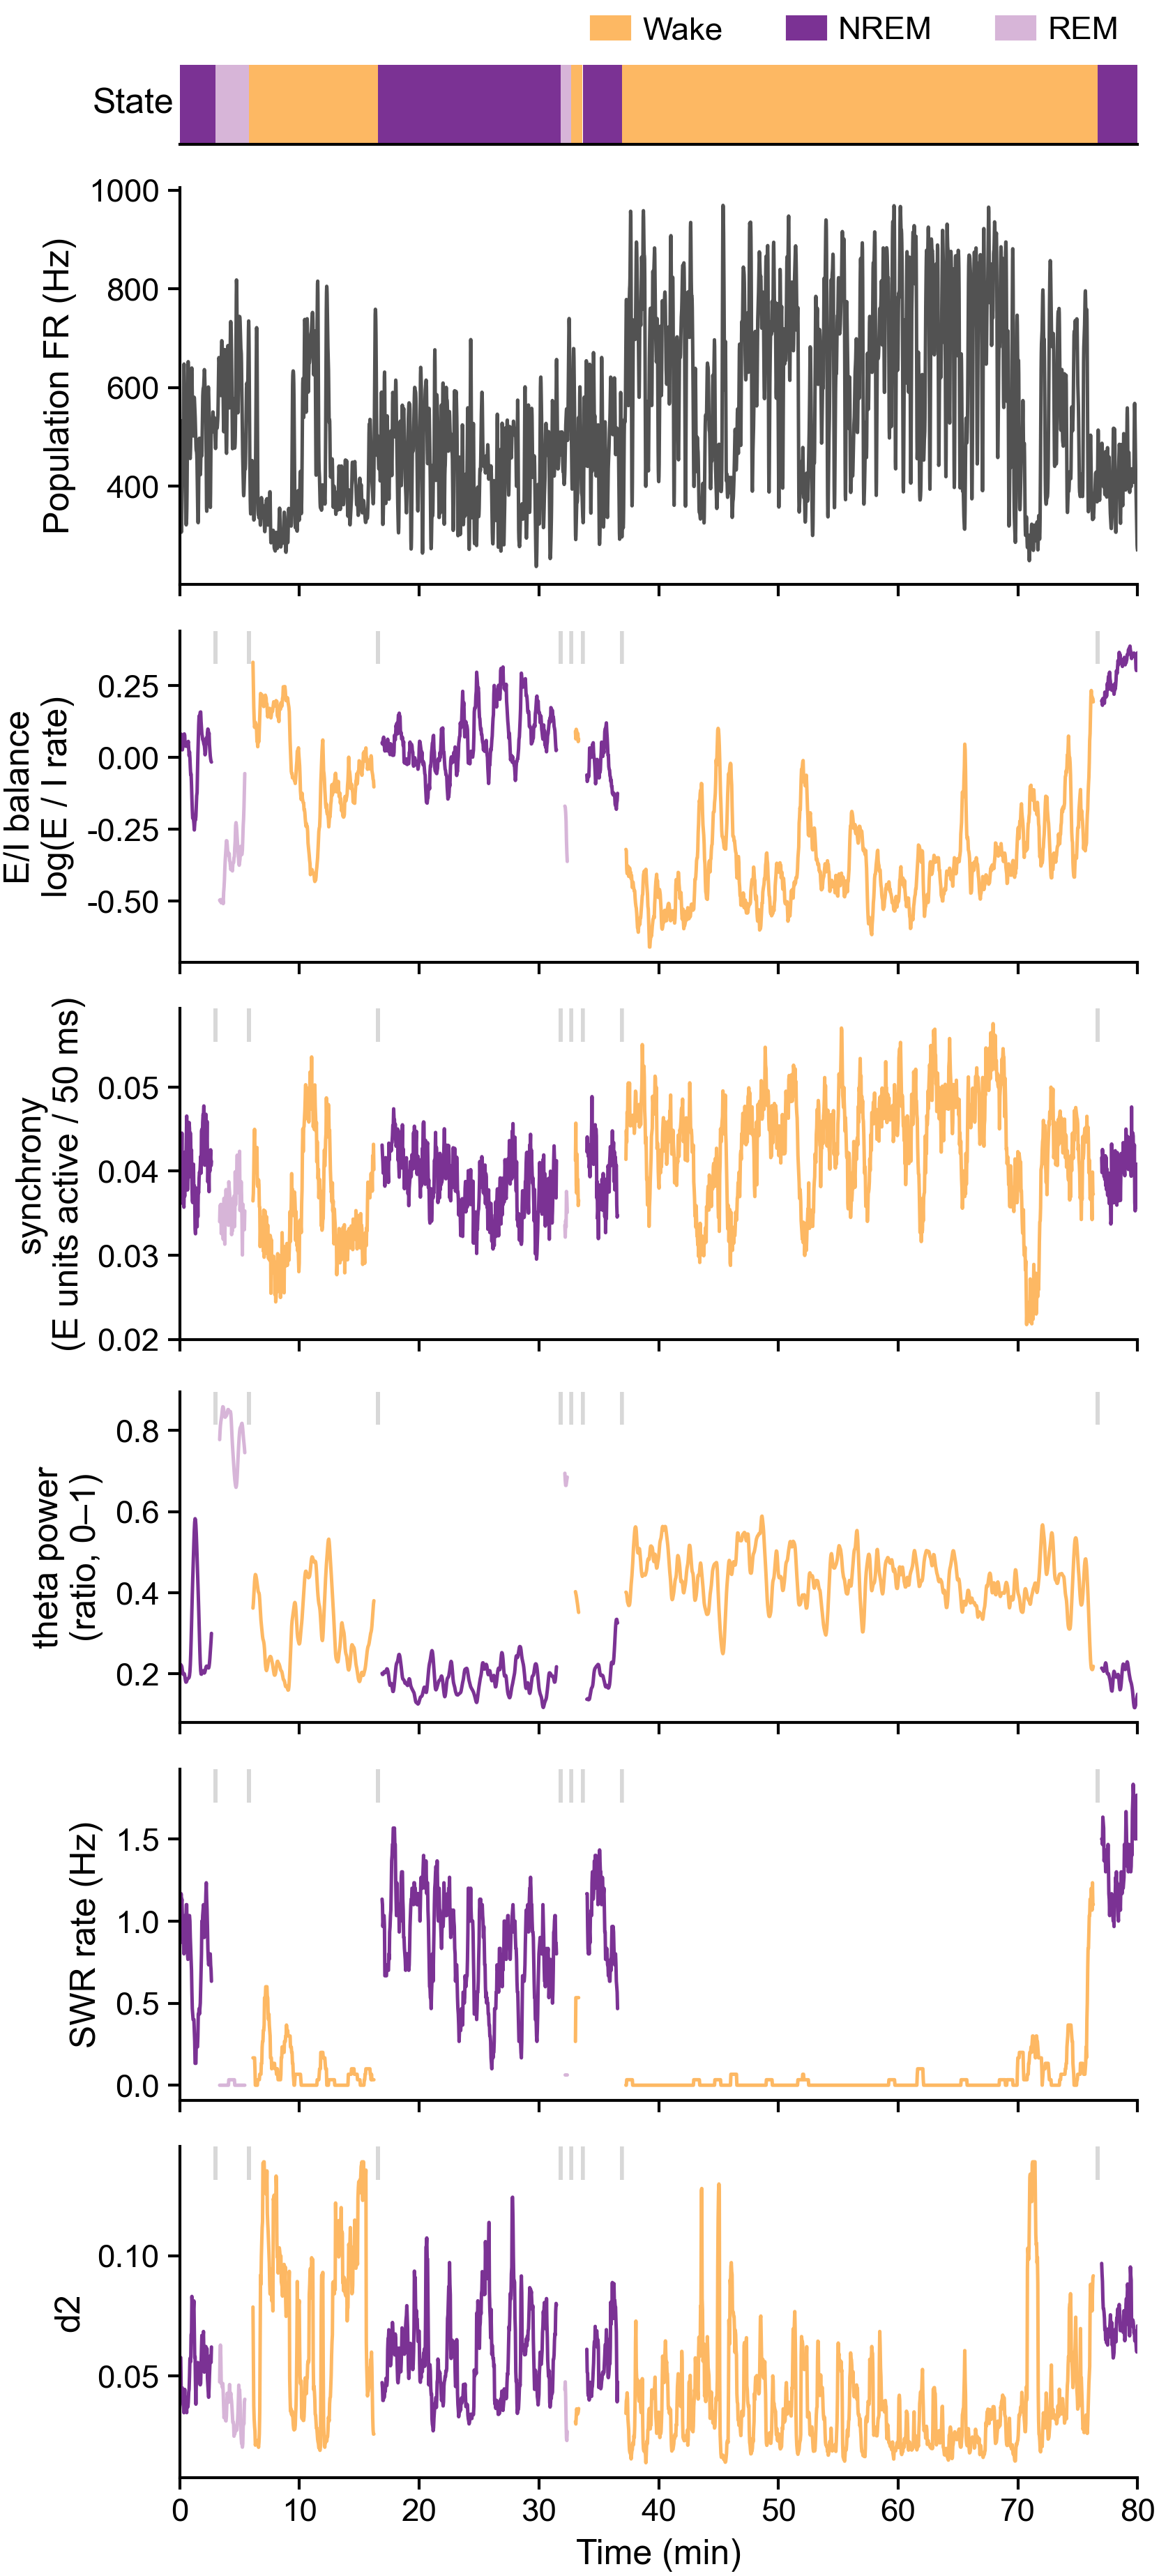

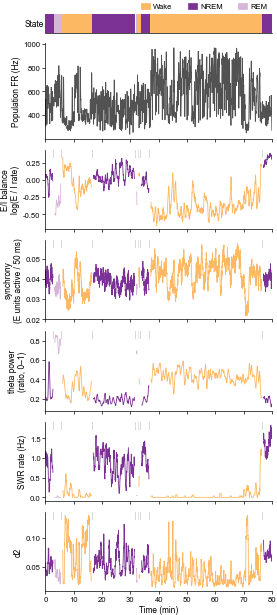

In [3]:
import tempfile
import pandas as pd
import fig1c_example_traces_drawing as M   # fig1c_example_traces.py's figure code (copied)

F.final_style(6)                                   # after the import: the producer sets 12 pt at import
M.FIGSIZE, M.LW, M.STATE_LABELPAD, M.DPI = (72 * F.MM, 158 * F.MM), 0.6, 8, 600
M.D2_LABEL = "d2"  # final figures say only "d2": the paper uses one definition, d2 (2024 Euclidean)
M.OUT = F.stem("Fig1_B_example_traces")           # the producer's figure path -> reports/revision_final/Fig1/
# ---- data (../csv) ----
# what fig1c_example_traces.main() computed from the recording (W:\\data\\PPP\\PPP20\\day5), then drawn by
# its own figure code: per 30 s window d2, E/I, synchrony, theta, SWR rate; the state labels;
# the 40 ms population rate of the plotted range and its whole-session 99.5th percentile (the cap)
D = read_csv('fig1b_windows.csv')
_st = read_csv('fig1b_states.csv')
iv = {k: _st[_st.state == k][['start', 'stop']].to_numpy(float).reshape(-1, 2) for k in ('WAKE', 'NREM', 'REM')}
_mua = read_csv('fig1b_mua_40ms.csv')
with F.retry_savefig():
    M.draw_figure(D, iv, _mua.time_s.to_numpy(), _mua.fr.to_numpy(), float(read_csv('fig1b_mua_cap.csv').fr_cap[0]))
# ---- the same from the recordings, with analysis_scripts/: ----
# STORED = M.OUT_CSV                                 # its window table, data/revision/log/fig1c_example_traces.csv
# M.OUT_CSV = os.path.join(tempfile.mkdtemp(), "fig1c_example_traces_check.csv")   # rerun's copy, compared below
# with F.retry_savefig():
#     M.main()
# a, b = pd.read_csv(STORED), pd.read_csv(M.OUT_CSV)
# num = a.select_dtypes("number").columns
# same = a.shape == b.shape and (a.state == b.state).all() and ((a[num] - b[num]).abs().max().max() < 1e-9)
# print(f"rerun table identical to {STORED}: {same}")
F.show(M.OUT + ".png")